# HW2 — Single Stock Risk Report

## 2.1 Parameters

In [1]:
# Parameters
ticker = "AAPL"
start_date = "2024-01-01"
end_date = "2024-12-31"
db_path = "data/data.db"

## 2.2 Data Loading

In [2]:
import sqlite3
from contextlib import closing
from datetime import date
from pathlib import Path

import pandas as pd

symbol = ticker.strip().upper()
start = date.fromisoformat(start_date)
end = date.fromisoformat(end_date)

if not symbol:
    raise ValueError("Enter a ticker symbol.")
if start > end:
    raise ValueError("The start date must be on or before the end date.")

query = """
SELECT ts, ticker, open, high, low, close, adj_close, volume
FROM ohlc_hw_cleaned
WHERE ticker = ? AND ts BETWEEN ? AND ?
ORDER BY ts
"""

db_uri = Path(db_path).resolve().as_uri() + "?mode=ro"
with closing(sqlite3.connect(db_uri, uri=True)) as connection:
    stock = pd.read_sql_query(
        query,
        connection,
        params=(symbol, start.isoformat(), end.isoformat()),
        parse_dates=["ts"],
    )

if stock.empty:
    raise ValueError(f"No prices found for {symbol} from {start} to {end}.")

print(f"{symbol} from {start} to {end}: {len(stock):,} trading days")
print(f"Actual coverage: {stock['ts'].min():%Y-%m-%d} to {stock['ts'].max():%Y-%m-%d}")

if len(stock) < 21:
    print("At least 21 prices are needed for 20 daily returns.")

display(stock.head())
display(stock.tail())

AAPL from 2024-01-01 to 2024-12-31: 202 trading days
Actual coverage: 2024-01-02 to 2024-10-18


,ts,ticker,open,high,low,close,adj_close,volume
0,2024-01-02,AAPL,187.15,188.44,183.89,185.64,184.94,82488674
1,2024-01-03,AAPL,184.22,185.88,183.43,184.25,183.55,58414460
2,2024-01-04,AAPL,182.15,183.09,180.88,181.91,181.22,71983570
3,2024-01-05,AAPL,181.99,182.76,180.17,181.18,180.50,62379661
4,2024-01-08,AAPL,182.09,185.60,181.50,185.56,184.86,59144470


,ts,ticker,open,high,low,close,adj_close,volume
197,2024-10-14,AAPL,228.70,231.73,228.60,231.30,231.30,39882100
198,2024-10-15,AAPL,233.61,237.49,232.37,233.85,233.85,64751400
199,2024-10-16,AAPL,231.60,232.12,229.84,231.78,231.78,34082240
200,2024-10-17,AAPL,233.43,233.85,230.52,232.15,232.15,32993810
201,2024-10-18,AAPL,236.18,236.18,234.01,235.00,235.00,45441281


## 2.3 Calculate Risk Metrics

In [3]:
import numpy as np

TRADING_DAYS = 252


def calculate_returns(prices: pd.Series) -> pd.Series:
    """Calculate daily log returns."""
    return np.log(prices / prices.shift(1))


def calculate_volatility(returns: pd.Series, window: int = 20) -> pd.Series:
    """Calculate annualized rolling volatility."""
    return returns.rolling(window).std(ddof=1) * np.sqrt(TRADING_DAYS)


def calculate_max_drawdown(prices: pd.Series) -> pd.Series:
    """Calculate each day's drawdown from the running price peak."""
    peak = prices.cummax()
    return (prices - peak) / peak


def calculate_sharpe_ratio(
    returns: pd.Series, risk_free_rate: float = 0.02
) -> float:
    """Calculate the annualized Sharpe ratio."""
    daily_std = returns.std(ddof=1)
    if pd.isna(daily_std) or daily_std == 0:
        return np.nan

    annual_excess_return = returns.mean() * TRADING_DAYS - risk_free_rate
    annual_volatility = daily_std * np.sqrt(TRADING_DAYS)
    return annual_excess_return / annual_volatility


stock["log_return"] = calculate_returns(stock["adj_close"])
stock["rolling_volatility"] = calculate_volatility(stock["log_return"])
stock["drawdown"] = calculate_max_drawdown(stock["adj_close"])

max_drawdown = stock["drawdown"].min()
sharpe = calculate_sharpe_ratio(stock["log_return"])
sharpe_display = "N/A" if pd.isna(sharpe) else f"{sharpe:.2f}"

print(f"Daily log returns: {stock['log_return'].count()}")
print(f"Maximum drawdown: {max_drawdown:.2%}")
print(f"Annualized Sharpe ratio: {sharpe_display}")

display(stock[["ts", "adj_close", "log_return", "rolling_volatility", "drawdown"]].tail())

Daily log returns: 201
Maximum drawdown: -15.35%
Annualized Sharpe ratio: 1.19


,ts,adj_close,log_return,rolling_volatility,drawdown
197,2024-10-14,231.30,0.016346,0.242503,-0.013856
198,2024-10-15,233.85,0.010964,0.243942,-0.002984
199,2024-10-16,231.78,-0.008891,0.241973,-0.011810
200,2024-10-17,232.15,0.001595,0.206097,-0.010232
201,2024-10-18,235.00,0.012202,0.209521,0.000000


## 2.4 Visualization

In [4]:
stock["ma50"] = stock["adj_close"].rolling(50).mean()
mean_volatility = stock["rolling_volatility"].mean()

print(f"Available 50-day averages: {stock['ma50'].count()}")
print(f"Mean annualized rolling volatility: {mean_volatility:.2%}")

display(stock[["ts", "adj_close", "ma50", "rolling_volatility"]].tail())

Available 50-day averages: 153
Mean annualized rolling volatility: 23.36%


,ts,adj_close,ma50,rolling_volatility
197,2024-10-14,231.30,223.6422,0.242503
198,2024-10-15,233.85,224.1386,0.243942
199,2024-10-16,231.78,224.6344,0.241973
200,2024-10-17,232.15,225.0858,0.206097
201,2024-10-18,235.00,225.5246,0.209521


Matplotlib is building the font cache; this may take a moment.


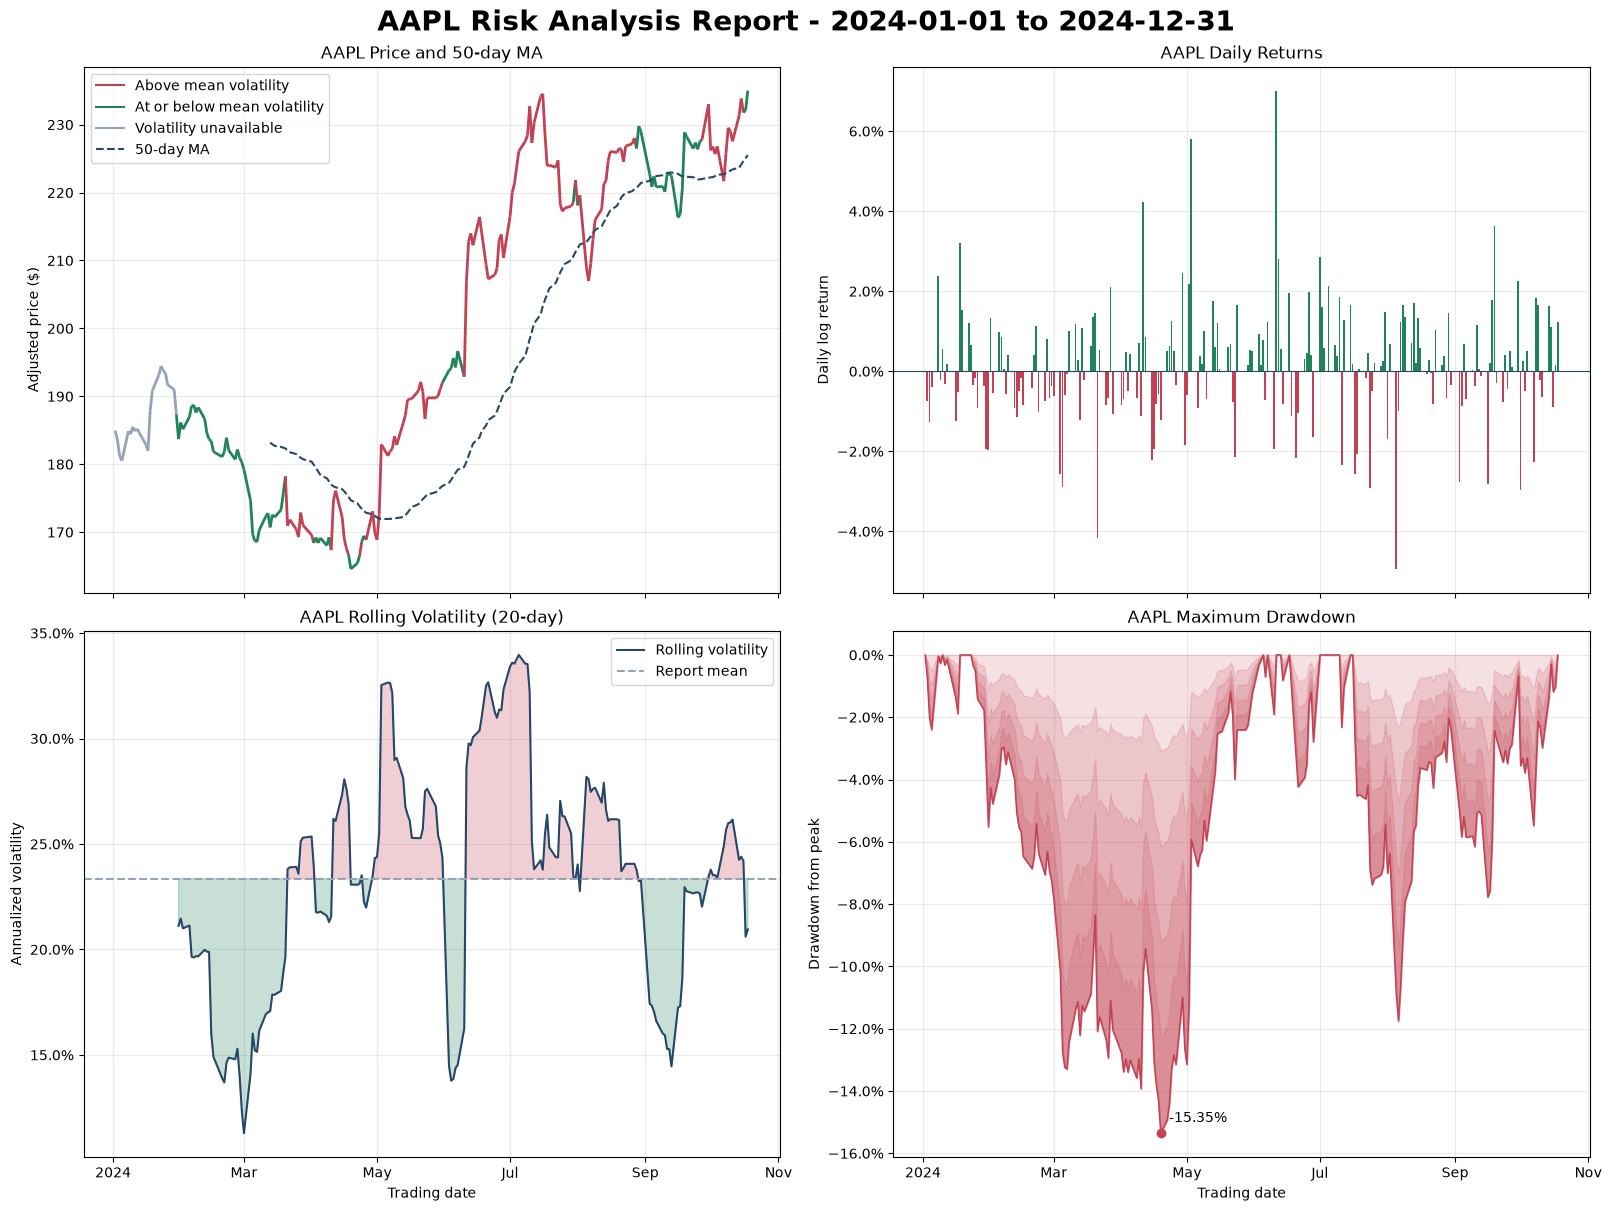

In [5]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from matplotlib.lines import Line2D
from matplotlib.ticker import PercentFormatter

dates = mdates.date2num(stock["ts"].to_numpy())
prices = stock["adj_close"].to_numpy()
returns = stock["log_return"].to_numpy()
volatility = stock["rolling_volatility"].to_numpy()
drawdown = stock["drawdown"].to_numpy()

red = "#C24152"
green = "#21835A"
gray = "#94A3B8"
navy = "#25476A"

fig, ((ax_price, ax_returns), (ax_vol, ax_drawdown)) = plt.subplots(
    2, 2, figsize=(16, 12), sharex=True, layout="constrained"
)
fig.suptitle(
    f"{symbol} Risk Analysis Report - {start_date} to {end_date}",
    fontsize=20,
    fontweight="bold",
)

# Top left: color each price segment by volatility on its ending date.
price_colors = np.full(len(stock), gray)
price_colors[volatility > mean_volatility] = red
price_colors[volatility <= mean_volatility] = green

points = np.column_stack((dates, prices))
segments = np.stack((points[:-1], points[1:]), axis=1)
ax_price.add_collection(
    LineCollection(segments, colors=price_colors[1:], linewidths=2)
)
if len(stock) == 1:
    ax_price.scatter(dates, prices, color=gray)

price_legend = [
    Line2D([0], [0], color=red, label="Above mean volatility"),
    Line2D([0], [0], color=green, label="At or below mean volatility"),
    Line2D([0], [0], color=gray, label="Volatility unavailable"),
]
if stock["ma50"].notna().any():
    (ma_line,) = ax_price.plot(
        dates, stock["ma50"], color=navy, linestyle="--", label="50-day MA"
    )
    price_legend.append(ma_line)
else:
    ax_price.text(
        0.02, 0.05, "50-day MA requires 50 prices", transform=ax_price.transAxes
    )

ax_price.autoscale_view()
ax_price.legend(handles=price_legend)
ax_price.set(title=f"{symbol} Price and 50-day MA", ylabel="Adjusted price ($)")

# Top right: green bars for gains and red bars for losses.
has_return = np.isfinite(returns)
return_colors = np.where(returns > 0, green, np.where(returns < 0, red, gray))
ax_returns.bar(dates[has_return], returns[has_return], color=return_colors[has_return])
ax_returns.axhline(0, color=navy, linewidth=0.8)
ax_returns.set(title=f"{symbol} Daily Returns", ylabel="Daily log return")

# Bottom left: shade volatility above and below its mean.
ax_vol.plot(dates, volatility, color=navy, label="Rolling volatility")
if np.isfinite(mean_volatility):
    ax_vol.axhline(mean_volatility, color=gray, linestyle="--", label="Report mean")
    for mask, color in [
        (volatility > mean_volatility, red),
        (volatility < mean_volatility, green),
    ]:
        ax_vol.fill_between(
            dates, volatility, mean_volatility,
            where=mask, interpolate=True, color=color, alpha=0.25,
        )
    ax_vol.legend()
else:
    ax_vol.text(0.02, 0.05, "Requires 20 daily returns", transform=ax_vol.transAxes)

ax_vol.set(title=f"{symbol} Rolling Volatility (20-day)", ylabel="Annualized volatility")

# Bottom right: layer translucent fills and mark the deepest drawdown.
for fraction in np.linspace(0, 0.8, 5):
    ax_drawdown.fill_between(dates, drawdown, fraction * drawdown, color=red, alpha=0.16)

ax_drawdown.plot(dates, drawdown, color=red, linewidth=1)
worst_date = dates[drawdown.argmin()]
ax_drawdown.scatter(worst_date, max_drawdown, color=red, zorder=3)
ax_drawdown.annotate(
    f"{max_drawdown:.2%}", (worst_date, max_drawdown),
    xytext=(6, 8), textcoords="offset points",
)
ax_drawdown.set(title=f"{symbol} Maximum Drawdown", ylabel="Drawdown from peak")

for ax in (ax_returns, ax_vol, ax_drawdown):
    ax.yaxis.set_major_formatter(PercentFormatter(xmax=1))

for ax in (ax_price, ax_returns, ax_vol, ax_drawdown):
    ax.set_axisbelow(True)
    ax.grid(alpha=0.25)

for ax in (ax_vol, ax_drawdown):
    ax.set_xlabel("Trading date")

locator = mdates.AutoDateLocator(minticks=4, maxticks=8)
ax_drawdown.xaxis.set_major_locator(locator)
ax_drawdown.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))

plt.show()

## 2.5 Summary Statistics Table

In [6]:
daily_returns = stock["log_return"].dropna()
adjusted_close = stock["adj_close"]

total_return = adjusted_close.iloc[-1] / adjusted_close.iloc[0] - 1
annualized_return = np.expm1(daily_returns.mean() * TRADING_DAYS)
annualized_volatility = daily_returns.std(ddof=1) * np.sqrt(TRADING_DAYS)

up_days = daily_returns[daily_returns > 0]
down_days = daily_returns[daily_returns < 0]
positive_days = (daily_returns > 0).mean()

summary_rows = [
    ("Total Return", total_return, "+.2%"),
    ("Annualized Return", annualized_return, "+.2%"),
    ("Annualized Volatility", annualized_volatility, ".2%"),
    ("Sharpe Ratio", sharpe, ".2f"),
    ("Maximum Drawdown", max_drawdown, ".2%"),
    ("Best Day", daily_returns.max(), "+.2%"),
    ("Worst Day", daily_returns.min(), "+.2%"),
    ("Positive Days", positive_days, ".1%"),
    ("Average Up Day", up_days.mean(), "+.2%"),
    ("Average Down Day", down_days.mean(), "+.2%"),
]

summary_table = pd.DataFrame(
    [
        (metric, "N/A" if pd.isna(value) else format(value, display_format))
        for metric, value, display_format in summary_rows
    ],
    columns=["Metric", "Value"],
)

display(summary_table.set_index("Metric"))

,Value
Metric,
Total Return,+27.07%
Annualized Return,+35.03%
Annualized Volatility,23.61%
Sharpe Ratio,1.19
Maximum Drawdown,-15.35%
Best Day,+7.01%
Worst Day,-4.94%
Positive Days,55.7%
Average Up Day,+1.08%


### Metrics for the batch script

In [7]:
from IPython.display import JSON

numeric_metrics = {
    "avg_daily_return": daily_returns.mean(),
    "avg_volatility": mean_volatility,
    "max_drawdown": max_drawdown,
    "sharpe_ratio": sharpe,
    "total_return": total_return,
}

portfolio_metrics = {
    "ticker": symbol,
    "actual_start": stock["ts"].iloc[0].strftime("%Y-%m-%d"),
    "actual_end": stock["ts"].iloc[-1].strftime("%Y-%m-%d"),
    "trading_days": len(stock),
}

for name, value in numeric_metrics.items():
    portfolio_metrics[name] = float(value) if np.isfinite(value) else None

display(JSON({"portfolio_metrics": portfolio_metrics}))

<IPython.core.display.JSON object>